[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/neurogym/neurogym/blob/main/docs/examples/supervised_learning_pytorch.ipynb)


## Neurogym with Supervised Learning (pytorch)

Pytorch-based example code for training a RNN on a perceptual decision-making task.


### Installation

**Google Colab:** Uncomment and execute cell below when running this notebook on google colab.

**Local:** Follow [these instructions](https://github.com/neurogym/neurogym?tab=readme-ov-file#installation) when running
this notebook locally.


In [1]:
# ! pip install neurogym

### Import libraries


In [2]:
import numpy as np
import torch
import torch.nn as nn

import neurogym as ngym

import warnings
from IPython.display import clear_output
from torch.nn import functional as F

from matplotlib import pyplot as plt
clear_output()
warnings.filterwarnings('ignore')


### Dataset


In [3]:
# Environment
task = 'PerceptualDecisionMaking-v0'
kwargs = {'dt': 100}
seq_len = 100

# Make supervised dataset
dataset = ngym.Dataset(task, env_kwargs=kwargs, batch_size=16,
                       seq_len=seq_len)
env = dataset.env
ob_size = env.observation_space.shape[0]
act_size = env.action_space.n

def get_temperature(time_step):
    max_temp = 1.0
    min_temp = 0.01
    decay_steps = 500
    if time_step < decay_steps * 3:
        temp = (max_temp - min_temp) * np.exp(-time_step / decay_steps) + min_temp
    else:
        temp = -1
    return temp

### Network and Training


In [4]:
# This settings is low to speed up testing; we recommend setting it to at least 2000
EPOCHS = 2000
from pdm_model import EISepLSTM, Net, load_model, SimpleNet

device = 'cuda' if torch.cuda.is_available() else 'cpu'
# net = Net(num_h=64, ob_size=ob_size, act_size=act_size).to(device)
net = Net(num_h=64, ob_size=ob_size, act_size=act_size).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=1e-2)

running_loss = 0.0
running_entropy = 0.0
running_decoding_loss = 0.0
for i in range(EPOCHS):
    # net.set_temperature(get_temperature(i))
    # if i % 10 == 9:
        # print('Epoch:', i+1, 'Temperature:', net.temperature)
    inputs, labels = dataset()
    inputs = torch.from_numpy(inputs).type(torch.float).to(device)
    labels = torch.from_numpy(labels.flatten()).type(torch.long).to(device)

    # zero the parameter gradients
    optimizer.zero_grad()

    # forward + backward + optimize
    outputs, eimask_logit, hidden = net(inputs)

    eimask_prob = F.softmax(eimask_logit, dim=-1)
    eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)

    decoding_loss = criterion(outputs.view(-1, act_size), labels)
    entropy_loss = torch.mean(eimask_entropy)  # Add entropy regularization

    # loss = decoding_loss
    loss = decoding_loss + entropy_loss * 1

    loss.backward()
    optimizer.step()

    # print statistics
    running_loss += loss.item()
    # running_entropy += entropy_loss.item()
    running_decoding_loss += decoding_loss.item()
    if (i+1) % 100 == 0:
        print('{:d} loss: {:0.5f}'.format(i+1, running_loss / 100))
        print('Entropy loss: {:0.5f}, Decoding loss: {:0.5f}'.format(
            running_entropy / 100, running_decoding_loss / 100))
        running_loss = 0.0

print('Finished Training')

100 loss: 0.59452
Entropy loss: 0.00000, Decoding loss: 0.17936
200 loss: 0.21880
Entropy loss: 0.00000, Decoding loss: 0.21254
300 loss: 0.10882
Entropy loss: 0.00000, Decoding loss: 0.23403
400 loss: 0.06550
Entropy loss: 0.00000, Decoding loss: 0.24979
500 loss: 0.04540
Entropy loss: 0.00000, Decoding loss: 0.26280
600 loss: 0.03577
Entropy loss: 0.00000, Decoding loss: 0.27563
700 loss: 0.02938
Entropy loss: 0.00000, Decoding loss: 0.28781
800 loss: 0.02553
Entropy loss: 0.00000, Decoding loss: 0.29991
900 loss: 0.02211
Entropy loss: 0.00000, Decoding loss: 0.31121
1000 loss: 0.02128
Entropy loss: 0.00000, Decoding loss: 0.32359
1100 loss: 0.01841
Entropy loss: 0.00000, Decoding loss: 0.33453
1200 loss: 0.01870
Entropy loss: 0.00000, Decoding loss: 0.34688
1300 loss: 0.01696
Entropy loss: 0.00000, Decoding loss: 0.35837
1400 loss: 0.01648
Entropy loss: 0.00000, Decoding loss: 0.37008
1500 loss: 0.01524
Entropy loss: 0.00000, Decoding loss: 0.38114
1600 loss: 0.01556
Entropy loss: 0

### Analysis


In [5]:
perf = 0
num_trial = 200
net.eval()
for i in range(num_trial):
    env.new_trial()
    ob, gt = env.ob, env.gt
    ob = ob[:, np.newaxis, :]  # Add batch axis
    inputs = torch.from_numpy(ob).type(torch.float).to(device)
    action_pred = net(inputs)[0]
    action_pred = action_pred.cpu().detach().numpy()
    action_pred = np.argmax(action_pred, axis=-1)
    perf += gt[-1] == action_pred[-1, 0]

perf /= num_trial
print('Average performance in {:d} trials'.format(num_trial))
print(perf)

Average performance in 200 trials
0.915


In [6]:
# corrected_weight = net.lstm.Wrec.cpu().detach().numpy()
# fig, ax = plt.subplots(figsize=(8, 6))
# im = ax.imshow(corrected_weight, cmap='coolwarm', vmin=-1, vmax=1)
# plt.colorbar(im, ax=ax)

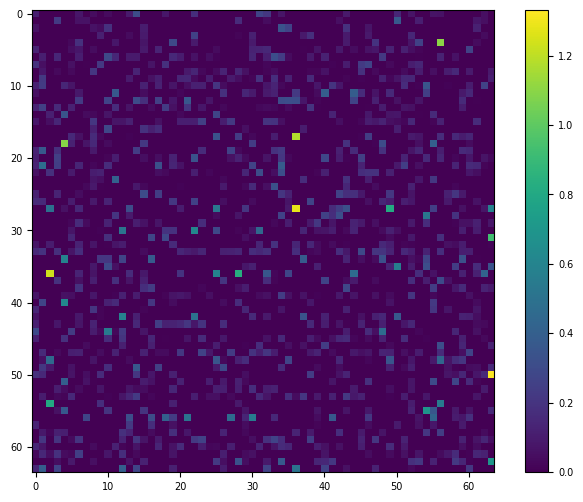

In [7]:
weight = net.lstm.Wrec_free
corrected_weight = net.lstm.rec_filter(weight).detach().cpu().numpy()  # Apply the rectifier
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corrected_weight)
plt.colorbar(im, ax=ax)

Percentage of excitatory neurons: 0.41
[ 2  4  5  7  9 15 16 18 24 25 28 29 30 36 37 39 41 43 46 49 50 55 57 58
 62 63]


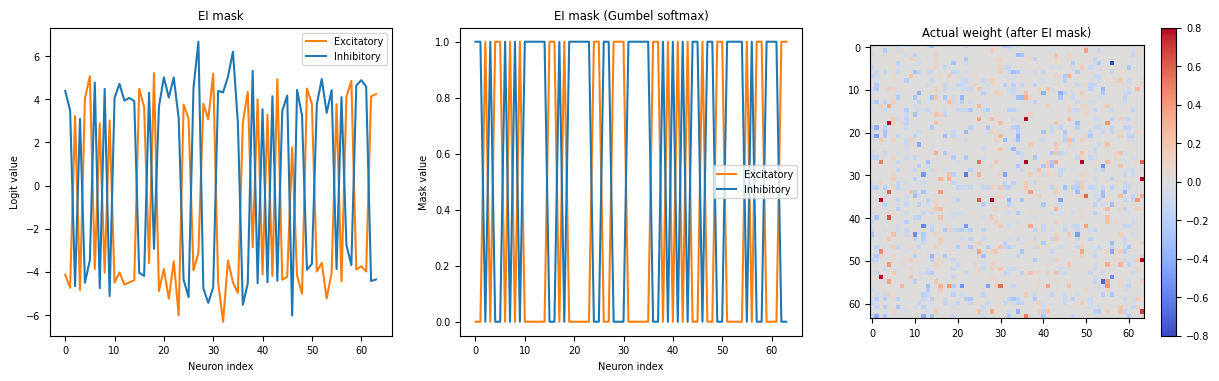

In [8]:
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
# mask = F.gumbel_softmax(net.lstm.eimask_logit, tau=0.1, hard=False, dim=-1).detach().cpu().numpy()
ei_code = np.where(eimask[:, 0] > eimask[:, 1], 1., -1.)
mask = np.where(ei_code.reshape(-1,1)>0, np.array([[1,0]]).repeat(eimask.shape[0], axis=0),
                np.array([[0,1]]).repeat(eimask.shape[0], axis=0))
# Apply the mask to the weight
actual_weight = corrected_weight @ np.diag(ei_code)  # Apply the mask to the weight
fig, ax = plt.subplots(1,3,figsize=(15, 4))
ax[0].plot(eimask[:, 0], label='Excitatory', color='C1')
ax[0].plot(eimask[:, 1], label='Inhibitory', color='C0')
ax[0].set_title('EI mask')
ax[0].set_xlabel('Neuron index')
ax[0].set_ylabel('Logit value')
ax[0].legend()
ax[1].plot(mask[:, 0], label='Excitatory', color='C1')
ax[1].plot(mask[:, 1], label='Inhibitory', color='C0')
ax[1].set_title('EI mask (Gumbel softmax)')
ax[1].set_xlabel('Neuron index')
ax[1].set_ylabel('Mask value')
ax[1].legend()
# normalized_weight = (actual_weight - np.min(actual_weight))/(np.max(actual_weight) - np.min(actual_weight)) * 2 - 1  # Normalize to [-1, 1]
im = ax[2].imshow(actual_weight, cmap='coolwarm', vmin=-0.8, vmax=0.8)
ax[2].set_title('Actual weight (after EI mask)')
plt.colorbar(im, ax=ax[2])
excitatory_neurons = np.where(mask[:, 0] > mask[:, 1],1,0).mean()
print(f'Percentage of excitatory neurons: {excitatory_neurons:.2f}')
print(np.where(mask[:, 0] > mask[:, 1])[0])

In [ ]:
# torch.save(net.state_dict(), './model/perceptualdecisionmaking/reluact_relutraining_entropy1.pth')